In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from mpl_toolkits.mplot3d import Axes3D

/var/folders/0p/2d3480md4n57dj4kyxxyxq6h0000gn/T/ipykernel_82966/2631315909.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


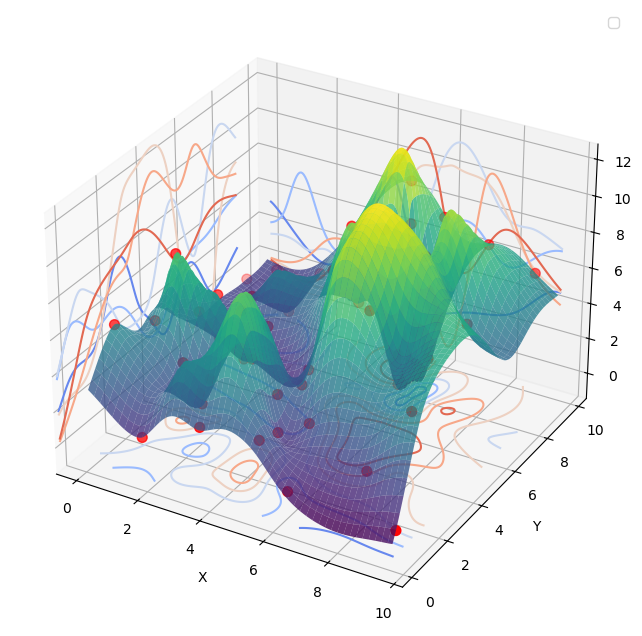

In [15]:
num_points = 50
x = np.random.rand(num_points) * 10
y = np.random.rand(num_points) * 10
z = np.random.rand(num_points) * 10 

data_coords = np.vstack((x, y)).T 
data_values = z              

rbf_interpolator = RBFInterpolator(data_coords, data_values, )

grid_x, grid_y = np.mgrid[x.min():x.max():200j, y.min():y.max():200j]

grid_coords = np.vstack((grid_x.ravel(), grid_y.ravel())).T
grid_z = rbf_interpolator(grid_coords)
grid_z = grid_z.reshape(grid_x.shape) # Reshape back to the grid structure

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(grid_x, grid_y, grid_z, cmap='viridis', alpha=0.8)

ax.scatter(x, y, z, color='r', s=50)

ax.contour(grid_x, grid_y, grid_z, zdir='z', offset=-1, cmap='coolwarm')
ax.contour(grid_x, grid_y, grid_z, zdir='x', offset=-1, cmap='coolwarm')
ax.contour(grid_x, grid_y, grid_z, zdir='y', offset=10, cmap='coolwarm')

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()

plt.show()

In [5]:
# dill the interpolator to use in another file
import dill

In [12]:
with open('rbf_interpolator.pkl', 'wb') as f:
    dill.dump(rbf_interpolator, f)

In [17]:
rbf_interpolator(grid_coords)

array([3.01494589, 3.12080367, 3.22676545, ..., 4.74761692, 4.73872566,
       4.73001524], shape=(40000,))

In [18]:
np.shape(grid_coords)

(40000, 2)